In [1]:
pip install numpy matplotlib seaborn tensorflow scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
import sklearn.metrics

In [3]:
DATA_DIR = "mudra_dataset" 
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Classes found:", class_names)


class_counts = []
for images, labels in train_ds.unbatch():
    class_counts.append(labels.numpy())

plt.figure(figsize=(8, 5))
sns.countplot(x=class_counts)
plt.title("Class Distribution in Training Data")
plt.xticks(ticks=range(len(class_names)), labels=class_names)
plt.show()

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'mudra_dataset'

In [5]:
# augmentation pipeline inside the model architecture
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

#Visualize augmented samples
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        # Apply augmentation to the first image 
        augmented_image = data_augmentation(tf.expand_dims(images[0], 0))
        plt.imshow(augmented_image[0].numpy().astype("uint8"))
        plt.title(class_names[labels[0]])
        plt.axis("off")
plt.show()

NameError: name 'train_ds' is not defined

<Figure size 1000x1000 with 0 Axes>

In [17]:
#CNN model
model = models.Sequential([

    # Augmentation and Normalization layer
    data_augmentation,
    layers.Rescaling(1./255, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    
    #Convolutional layers
    layers.Conv2D(32, (3, 3), activation='relu'),

    layers.MaxPooling2D(2, 2),
    
    layers.Conv2D(64, (3, 3), activation='relu'),

    layers.MaxPooling2D(2, 2),
    
    layers.Conv2D(128, (3, 3), activation='relu'),

    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5), 
    layers.Dense(len(class_names), activation='softmax')
])

C:\Users\adith\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15


C:\Users\adith\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 341ms/step - accuracy: 0.5962 - loss: 0.9979 - val_accuracy: 0.9600 - val_loss: 0.1275
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 354ms/step - accuracy: 0.9144 - loss: 0.2608 - val_accuracy: 1.0000 - val_loss: 0.0099
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 337ms/step - accuracy: 0.9381 - loss: 0.1892 - val_accuracy: 0.9950 - val_loss: 0.0150
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 390ms/step - accuracy: 0.9681 - loss: 0.1090 - val_accuracy: 0.9950 - val_loss: 0.0126
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 393ms/step - accuracy: 0.9563 - loss: 0.1309 - val_accuracy: 1.0000 - val_loss: 0.0053
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 422ms/step - accuracy: 0.9631 - loss: 0.1032 - val_accuracy: 0.9950 - val_loss: 0.0094
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 497ms/step - accuracy: 0.9675 - loss: 0.1006 - val_accuracy: 0.9975 - val_loss: 0.0108
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 378ms/step - accuracy: 0.9700 - loss: 0.0893 - val_accuracy: 1.000

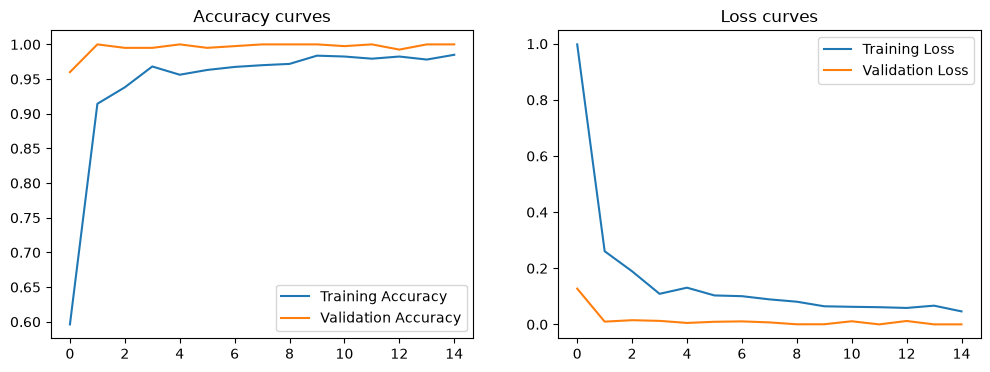

In [18]:
#learning rate 
custom_optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer=custom_optimizer,
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train model
epochs = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

# Ploting training&validation curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy curves')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss curves')
plt.show()

In [19]:
# truelabels and predictions
y_true = []
y_pred = []
y_pred_probs = []
images_list = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))
    y_pred_probs.extend(np.max(preds, axis=1))
    images_list.extend(images.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_pred_probs = np.array(y_pred_probs)
images_list = np.array(images_list)

              precision    recall  f1-score   support

       Musti       1.00      1.00      1.00        71
      Pataka       1.00      1.00      1.00        77
     Sikhara       1.00      1.00      1.00        77
  Simhamukha       1.00      1.00      1.00        85
     Trisula       1.00      1.00      1.00        90

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



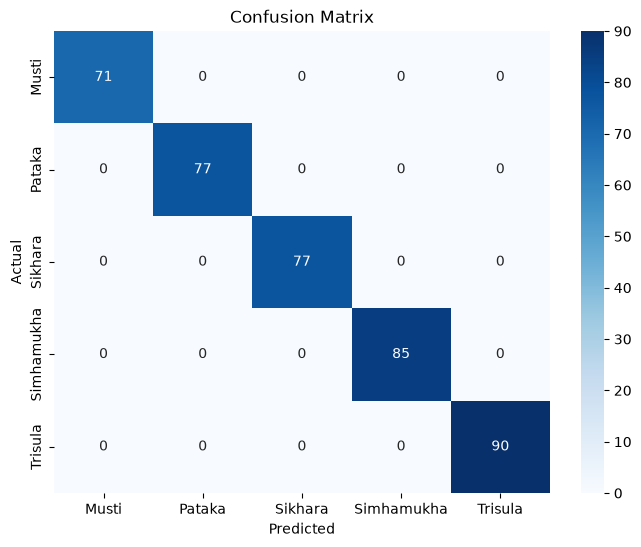

In [20]:
# Classification Report
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [22]:
# Display misclassified images
misclassified_indices = np.where(y_true != y_pred)[0]

plt.figure(figsize=(15, 10))
for i, idx in enumerate(misclassified_indices[:15]): # Show up to 15
    plt.subplot(3, 5, i + 1)
    plt.imshow(images_list[idx].astype("uint8"))
    actual_label = class_names[y_true[idx]]
    predicted_label = class_names[y_pred[idx]]
    conf_score = y_pred_probs[idx] * 100
    
    plt.title(f"Act: {actual_label}\nPred: {predicted_label}\nConf: {conf_score:.1f}%", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()
# Save the model for Streamlit deployment
model.save("mudra_model.keras")
print("Model saved as mudra_model.keras")

<Figure size 1500x1000 with 0 Axes>

Model saved as mudra_model.keras


In [23]:
# Using MobileNetV2 
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False # Freeze base model

tl_model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1), # MobileNetV2 expects [-1, 1]
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

tl_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
tl_history = tl_model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10


C:\Users\adith\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 23s 385ms/step - accuracy: 0.9025 - loss: 0.2753 - val_accuracy: 1.0000 - val_loss: 0.0144
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 314ms/step - accuracy: 0.9944 - loss: 0.0230 - val_accuracy: 1.0000 - val_loss: 0.0086
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 307ms/step - accuracy: 0.9987 - loss: 0.0144 - val_accuracy: 1.0000 - val_loss: 0.0042
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 404ms/step - accuracy: 0.9981 - loss: 0.0093 - val_accuracy: 1.0000 - val_loss: 0.0050
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 359ms/step - accuracy: 0.9975 - loss: 0.0083 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 349ms/step - accuracy: 0.9994 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 306ms/step - accuracy: 0.9975 - loss: 0.0078 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 261ms/step - accuracy: 0.9994 - loss: 0.0031 - val_accuracy: 1.000